In [1]:
import pandas as pd 
import numpy as np
import matplotlib.pyplot as plt

from sklearn.preprocessing import MinMaxScaler
from sklearn.metrics import mean_squared_error , mean_absolute_error

from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Dense ,LSTM


In [ ]:
df= pd.read_csv(r" - AirPassengers.csv")
df.head()

,Month,#Passengers
0,1949-01,112
1,1949-02,118
2,1949-03,132
3,1949-04,129
4,1949-05,121


In [3]:
df.columns

Index(['Month', '#Passengers'], dtype='str')

In [4]:
df.shape

(144, 2)

In [5]:
df.describe()

,#Passengers
count,144.000000
mean,280.298611
std,119.966317
min,104.000000
25%,180.000000
50%,265.500000
75%,360.500000
max,622.000000


In [6]:
df.isnull().sum()

Month          0
#Passengers    0
dtype: int64

In [10]:
 data = df["#Passengers"].values.reshape(-1,1)
 len(data)

144

In [11]:
#normalize
scaler=MinMaxScaler()
data = scaler.fit_transform(data)
print("Data Normalized Succesfully")

Data Normalized Succesfully


In [12]:
x=[]
y=[]

for i in range(12,len(data)):
    x.append(data[i-12:i])
    y.append(data[i])

x=np.array(x)
y=np.array(y)


In [13]:
print("x shape:",x.shape)
print("y shape:",y.shape)

x shape: (132, 12, 1)
y shape: (132, 1)


In [14]:
train=int(len(x)*0.8)

x_train=x[:train]
y_train = y[:train]


x_test=x[train:]
y_test = y[train:]

print("training samples: ",len(x_train) )
print("testing samples: ",len(x_test) )

training samples:  105
testing samples:  27


In [15]:
#build and compile
model=Sequential([
    LSTM(50, input_shape=(12,1)),
    Dense(1)
])

#compile

model.compile(optimizer='adam',loss='mse')

C:\Users\user\AppData\Local\Programs\Python\Python314\Lib\site-packages\keras\src\layers\rnn\rnn.py:199: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(**kwargs)


In [16]:
#train

model.fit(
    x_train,
    y_train,
    epochs=100,
    batch_size= 16
)

Epoch 1/100
7/7 ━━━━━━━━━━━━━━━━━━━━ 1s 75ms/step - loss: 0.0842
Epoch 2/100
7/7 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step - loss: 0.0232 
Epoch 3/100
7/7 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step - loss: 0.0128 
Epoch 4/100
7/7 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step - loss: 0.0121 
Epoch 5/100
7/7 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step - loss: 0.0100 
Epoch 6/100
7/7 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step - loss: 0.0095 
Epoch 7/100
7/7 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step - loss: 0.0080 
Epoch 8/100
7/7 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - loss: 0.0078 
Epoch 9/100
7/7 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step - loss: 0.0074 
Epoch 10/100
7/7 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - loss: 0.0072 
Epoch 11/100
7/7 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - loss: 0.0069 
Epoch 12/100
7/7 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step - loss: 0.0068 
Epoch 13/100
7/7 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - loss: 0.0067 
Epoch 14/100
7/7 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - loss: 0.0066 
Epoch 15/100
7/7 ━━━━━━━━━━━━━━━━━━━━ 0s 7ms/step - loss: 0.0065 
Epoch 16/100
7/7 ━━

In [17]:
predicted = model.predict(x_test)

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 125ms/step


In [18]:
predicted = scaler.inverse_transform(predicted)
actual = scaler.inverse_transform(y_test)

In [19]:
mse = mean_squared_error(actual,predicted)
mae = mean_absolute_error(actual,predicted)

print("mean_squared_error: ",mse)
print("mean_absolute_error: ",mae)

mean_squared_error:  1341.8195368772786
mean_absolute_error:  30.966393364800346


In [22]:
compare = pd.DataFrame({
    "Actual":actual.flatten(),
    "predicted": predicted.flatten()
})

compare.head(15)

,Actual,predicted
0,359.0,410.612671
1,310.0,368.249817
2,337.0,343.134949
3,360.0,339.058258
4,342.0,350.632812
5,406.0,368.469727
6,396.0,406.083710
7,420.0,435.663208
8,472.0,471.073364
9,548.0,500.546936


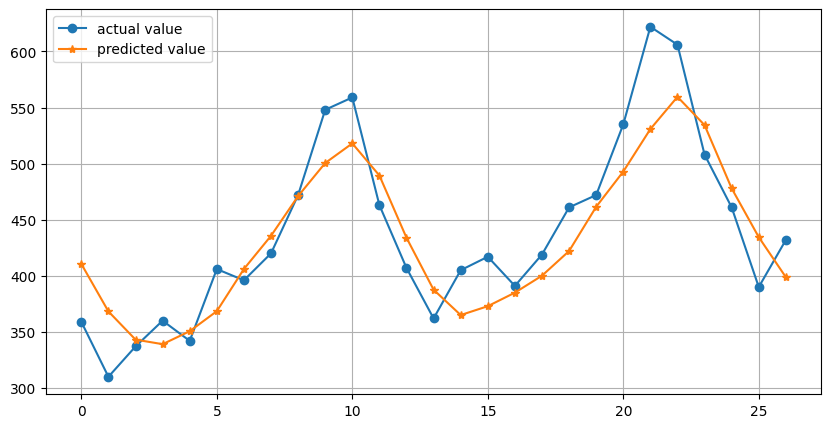

In [34]:
plt.figure(figsize=(10,5))

plt.plot(actual,
        label="actual value",
        marker="o")
plt.plot(predicted,
        label="predicted value",
        marker="*")
plt.grid(True)
plt.legend()

plt.show()